# 02 · Análisis exploratorio
**¿Qué separa a los videojuegos que venden más de un millón de copias del resto?**

Con el dataset limpio del [notebook 01](01_limpieza_y_auditoria.ipynb), este notebook recorre seis preguntas de negocio, cada una con su gráfico, su prueba estadística cuando hace falta y una lectura honesta de lo que el dato permite (y no permite) decir.

| # | Pregunta | Sección |
|---|---|---|
| 1 | ¿Qué tan concentrado está el éxito? | 2 |
| 2 | ¿Cómo cambió el mercado y qué vida tiene una consola? | 3 |
| 3 | ¿Qué géneros rinden más? | 4 |
| 4 | ¿Cada región tiene gustos distintos? | 5 |
| 5 | ¿Importan el publisher, la franquicia y salir en varias plataformas? | 6 |
| 6 | ¿Qué variable separa mejor las ventas? | 7 |

**Aviso de lectura.** Todo lo que sigue es **asociación**, no causalidad: el dato son ventas observadas de títulos que existen, no un experimento. «Éxito» significa **≥ 1 millón de copias vendidas en el mundo**.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm, to_hex
from matplotlib.patches import Patch
from scipy import stats

RAIZ = Path.cwd().parent                      # los notebooks se ejecutan desde notebooks/
sys.path.insert(0, str(RAIZ / "src"))
import estilo
import features as F
import limpieza as L

estilo.aplicar()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
SEMILLA = 0

## 1. Datos de partida y alcance

Se parte del archivo que dejó el notebook 01. Los análisis por título usan solo las fichas **sin registros parciales** y **dentro de la ventana 1995–2014**.

In [2]:
limpio = pd.read_csv(L.PROCESSED, dtype={"anio": "Int64"})

base = F.preparar_base(limpio)                                   # sin parciales ni años desconocidos; agrega n_versiones, publisher_grp...
base = pd.concat([base, F.historial_previo(base, "franquicia", "fr", rezago=0)], axis=1)   # ¿hubo entregas previas de la saga?
t = base[base["en_ventana"]].copy()                               # fichas analizables

alcance = pd.Series({
    "Fichas en el dataset limpio": len(limpio),
    "− registros parciales": -int(limpio["registro_parcial"].sum()),
    "− fuera de la ventana 1995–2014 (o sin año)": -int((~limpio["registro_parcial"] & ~limpio["en_ventana"]).sum()),
    "= fichas analizables": len(t),
}, name="fichas")
assert alcance.iloc[0] + alcance.iloc[1] + alcance.iloc[2] == alcance.iloc[3]
alcance.to_frame()

,fichas
Fichas en el dataset limpio,16596
− registros parciales,-151
− fuera de la ventana 1995–2014 (o sin año),-1711
= fichas analizables,14734


## 2. ¿Qué tan concentrado está el éxito?

Antes de buscar causas conviene saber cómo se reparten las ventas. Si fueran parejas, «el título medio» sería una buena referencia; si no, esa referencia engaña.

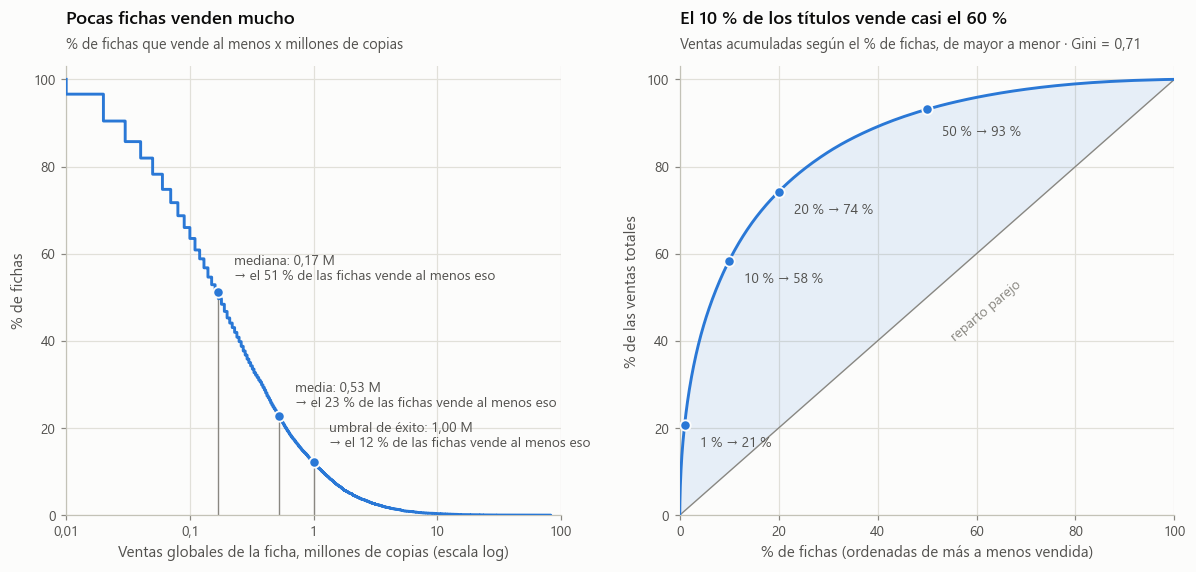

Fichas: 14,734 · mediana 0.17 M · media 0.53 M (×3.1) · fichas por encima de la media: 22.8%
Fichas que hacen falta para llegar a la mitad de las ventas: 995 (6.8%)
La mitad menos vendida de las fichas suma el 6.9 % de las ventas


In [3]:
def gini(x):
    x = np.sort(np.asarray(x, float))
    n = len(x)
    return 2 * np.sum(np.arange(1, n + 1) * x) / (n * x.sum()) - (n + 1) / n


ventas = t["ventas_global"]
mediana, media = ventas.median(), ventas.mean()
orden = ventas.sort_values(ascending=False).to_numpy()
acumulado = np.cumsum(orden) / orden.sum() * 100
pos = np.arange(1, len(orden) + 1) / len(orden) * 100
coef_gini = gini(orden)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.3), gridspec_kw={"wspace": 0.24})

# --- (a) cuántas fichas venden al menos x (escala logarítmica en x)
xs = np.sort(ventas.to_numpy())
sobrevive = (len(xs) - np.arange(len(xs))) / len(xs) * 100          # % de fichas con ventas >= x
ax1.plot(xs, sobrevive, color=estilo.AZUL, lw=1.9, drawstyle="steps-post", zorder=3)
ax1.set_xscale("log")
ax1.set_xlim(0.01, 100)
ax1.set_ylim(0, 103)
ax1.set_xticks([0.01, 0.1, 1, 10, 100], ["0,01", "0,1", "1", "10", "100"])
ax1.minorticks_off()
estilo.rejilla(ax1, "ambos")
estilo.titular(ax1, "Pocas fichas venden mucho", "% de fichas que vende al menos x millones de copias")
ax1.set_xlabel("Ventas globales de la ficha, millones de copias (escala log)")
ax1.set_ylabel("% de fichas")
puntos = [(mediana, "mediana", (10, 6)), (media, "media", (10, 4)), (1.0, "umbral de éxito", (10, 8))]
for x0, nombre, desplaz in puntos:
    y0 = (ventas >= x0).mean() * 100
    ax1.vlines(x0, 0, y0, color=estilo.APAGADO, lw=0.9, zorder=2)
    ax1.scatter([x0], [y0], s=46, color=estilo.AZUL, edgecolor=estilo.SUPERFICIE, linewidth=1.2, zorder=5)
    ax1.annotate(f"{nombre}: {estilo.num(x0, 2)} M\n→ el {estilo.num(y0, 0)} % de las fichas vende al menos eso",
                 (x0, y0), xytext=desplaz, textcoords="offset points", fontsize=9, color=estilo.TINTA_2, va="bottom")

# --- (b) curva de concentración
x_aug = np.r_[0, pos]
y_aug = np.r_[0, acumulado]
ax2.fill_between(x_aug, x_aug, y_aug, color=estilo.AZUL, alpha=0.10, lw=0, zorder=1)
ax2.plot([0, 100], [0, 100], color=estilo.APAGADO, lw=0.9, zorder=2)
ax2.plot(x_aug, y_aug, color=estilo.AZUL, lw=1.9, zorder=3)
ax2.set_xlim(0, 100)
ax2.set_ylim(0, 103)
estilo.rejilla(ax2, "ambos")
estilo.titular(ax2, "El 10 % de los títulos vende casi el 60 %", f"Ventas acumuladas según el % de fichas, de mayor a menor · Gini = {estilo.num(coef_gini, 2)}")
ax2.set_xlabel("% de fichas (ordenadas de más a menos vendida)")
ax2.set_ylabel("% de las ventas totales")
ax2.text(62, 47, "reparto parejo", rotation=40, color=estilo.APAGADO, fontsize=9, ha="center", va="center")
for q, desplaz in [(1, (10, -14)), (10, (10, -14)), (20, (10, -14)), (50, (10, -17))]:
    k = int(round(len(orden) * q / 100))
    ax2.scatter([q], [acumulado[k - 1]], s=46, color=estilo.AZUL, edgecolor=estilo.SUPERFICIE, linewidth=1.2, zorder=5)
    ax2.annotate(f"{q} % → {estilo.num(acumulado[k - 1], 0)} %", (q, acumulado[k - 1]), xytext=desplaz, textcoords="offset points",
                 fontsize=9, color=estilo.TINTA_2, ha="left" if desplaz[0] > 0 else "right")
estilo.guardar(fig, "fig04_distribucion_y_concentracion.png")
plt.show()

print(f"Fichas: {len(ventas):,} · mediana {mediana:.2f} M · media {media:.2f} M (×{media / mediana:.1f}) · fichas por encima de la media: {(ventas > media).mean():.1%}")
print(f"Fichas que hacen falta para llegar a la mitad de las ventas: {int((acumulado < 50).sum()) + 1:,} ({((acumulado < 50).sum() + 1) / len(orden):.1%})")
print(f"La mitad menos vendida de las fichas suma el {100 - acumulado[len(orden) // 2 - 1]:.1f} % de las ventas")

In [4]:
t.nlargest(10, "ventas_global")[["nombre", "plataforma", "anio", "publisher", "ventas_global"]].reset_index(drop=True)

,nombre,plataforma,anio,publisher,ventas_global
0,Wii Sports,Wii,2006,Nintendo,82.74
1,Mario Kart Wii,Wii,2008,Nintendo,35.82
2,Wii Sports Resort,Wii,2009,Nintendo,33.00
3,Pokemon Red/Pokemon Blue,GB,1996,Nintendo,31.37
4,New Super Mario Bros.,DS,2006,Nintendo,30.01
5,Wii Play,Wii,2006,Nintendo,29.02
6,New Super Mario Bros. Wii,Wii,2009,Nintendo,28.62
7,Nintendogs,DS,2005,Nintendo,24.76
8,Mario Kart DS,DS,2005,Nintendo,23.42
9,Pokemon Gold/Pokemon Silver,GB,1999,Nintendo,23.10


> **Hallazgo.** El éxito es una **cola larga**: el título medio vende 0,53 M, pero la mediana es de 0,17 M y solo el 23 % de las fichas alcanza siquiera la media. El 1 % de las fichas (≈ 150) concentra el 21 % de las ventas y el 10 % concentra el 58 %; la mitad menos vendida apenas suma un 7 %. Las 10 fichas más vendidas son todas de Nintendo.
>
> **Para el análisis:** el *promedio* de ventas es una mala medida del «título típico» (lo arrastran unos pocos superéxitos). Se usarán **medianas** y **tasa de éxito** (% de fichas ≥ 1 M); y como objetivo del modelo, la variable binaria `exito`, no las ventas en bruto.

## 3. ¿Cómo cambió el mercado?

### 3.1 Ventas por fabricante y año

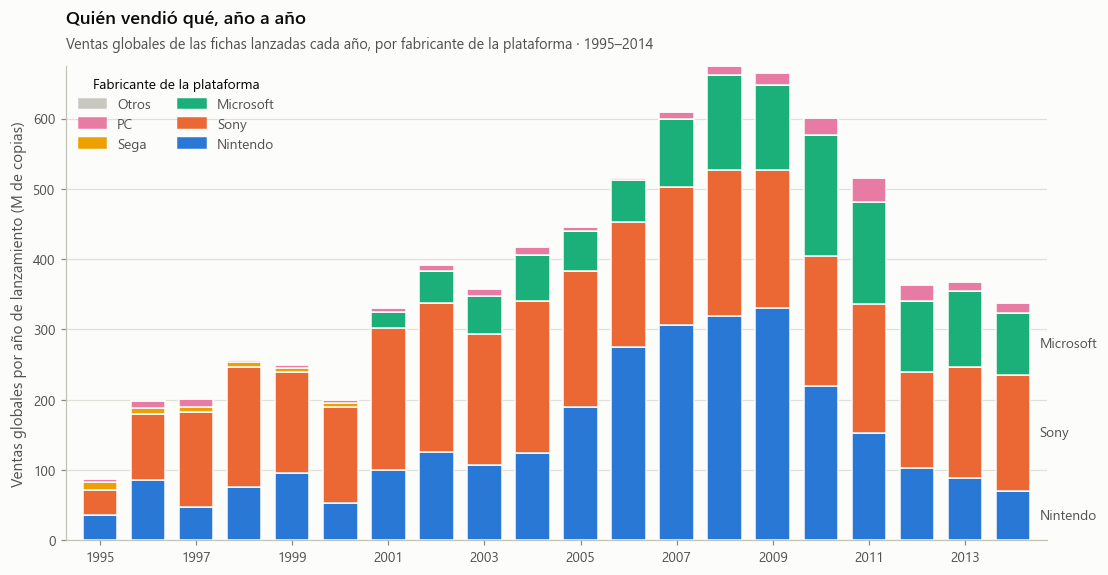

Cuota de ventas (%) por fabricante y periodo — tabla de apoyo de la figura


fabricante,Nintendo,Sony,Microsoft,Sega,PC,Otros,total (M)
anio,,,,,,,
1995–1999,34.2,58.4,0.0,3.9,3.4,0.1,994.3
2000–2004,30.0,56.1,11.1,0.4,2.3,0.1,1697.4
2005–2009,48.9,33.4,16.2,0.0,1.6,0.0,2909.4
2010–2014,29.1,37.8,28.1,0.0,5.0,0.0,2185.1
1995–2014,37.3,42.8,16.4,0.6,2.9,0.0,7786.2


In [5]:
orden_fab = ["Nintendo", "Sony", "Microsoft", "Sega", "PC", "Otros"]
por_anio = (t.pivot_table(index="anio", columns="fabricante", values="ventas_global", aggfunc="sum")
              .reindex(columns=orden_fab).fillna(0))
por_anio.index = por_anio.index.astype(int)

fig, ax = plt.subplots(figsize=(11.5, 5.6))
fondo = np.zeros(len(por_anio))
for fab in orden_fab:
    ax.bar(por_anio.index, por_anio[fab], bottom=fondo, width=0.72, color=estilo.COLOR_FABRICANTE[fab],
           edgecolor=estilo.SUPERFICIE, linewidth=1.0, label=fab, zorder=3)
    fondo += por_anio[fab].to_numpy()
ax.set_xlim(1994.3, 2014.7)
ax.set_xticks(range(1995, 2015, 2))
ax.yaxis.set_major_formatter(estilo.formato_eje())
ax.set_ylabel("Ventas globales por año de lanzamiento (M de copias)")
estilo.titular(ax, "Quién vendió qué, año a año", "Ventas globales de las fichas lanzadas cada año, por fabricante de la plataforma · 1995–2014")
for fab in ["Nintendo", "Sony", "Microsoft"]:                         # etiquetas directas junto al último año
    base_f = por_anio.loc[2014, orden_fab[:orden_fab.index(fab)]].sum()
    ax.text(2014.55, base_f + por_anio.loc[2014, fab] / 2, fab, va="center", ha="left", fontsize=9, color=estilo.TINTA_2, clip_on=False)
handles = [Patch(color=estilo.COLOR_FABRICANTE[f], label=f) for f in orden_fab[::-1]]
ax.legend(handles=handles, loc="upper left", frameon=False, ncol=2, title="Fabricante de la plataforma", title_fontsize=9)
estilo.guardar(fig, "fig05_ventas_por_fabricante.png")
plt.show()

periodo = pd.cut(t["anio"].astype(int), [1994, 1999, 2004, 2009, 2014], labels=["1995–1999", "2000–2004", "2005–2009", "2010–2014"])
cuota = t.pivot_table(index=periodo, columns="fabricante", values="ventas_global", aggfunc="sum", observed=True).reindex(columns=orden_fab).fillna(0)
cuota.loc["1995–2014"] = cuota.sum()                                     # fila de totales
tabla_cuota = cuota.div(cuota.sum(axis=1), axis=0) * 100
tabla_cuota["total (M)"] = cuota.sum(axis=1)
print("Cuota de ventas (%) por fabricante y periodo — tabla de apoyo de la figura")
tabla_cuota.round(1)

In [6]:
# ¿qué consolas explican el auge de Nintendo en 2005-2010?
nin = t[(t["fabricante"] == "Nintendo") & t["anio"].between(2005, 2010)].groupby("plataforma")["ventas_global"].sum().sort_values(ascending=False)
print((nin / nin.sum() * 100).round(1).head(4).to_dict())

{'Wii': 49.2, 'DS': 45.9, 'GBA': 2.5, 'GC': 2.4}


> **Hallazgo.** En el total de la ventana, Sony (≈ 43 % de las ventas) y Nintendo (≈ 37 %) se reparten el grueso del mercado y Microsoft, que entra en 2001, se queda con ≈ 16 %. Pero el reparto **cambia por épocas** (tabla): Sony pasa de dominar (58 % en 1995–99 y 56 % en 2000–04) a ≈ 33 % en 2005–09, mientras Nintendo salta de ≈ 30 % a ≈ 49 %, empujada casi por completo por **Wii y DS** (el 95 % de sus ventas de 2005–2010). Luego Nintendo vuelve a ≈ 29 % y Microsoft sube a ≈ 28 % (2010–14). Las ventas totales del dataset alcanzan su máximo en 2008 y bajan desde entonces, pero **no es seguro leerlo como una contracción del mercado**: la cobertura del dataset también cambia después de 2011 (notebook 01).

### 3.2 El ciclo de vida de una consola
Para cada plataforma con historia suficiente: ¿cuántas ventas se registran cada año desde su lanzamiento, relativas a su mejor año?

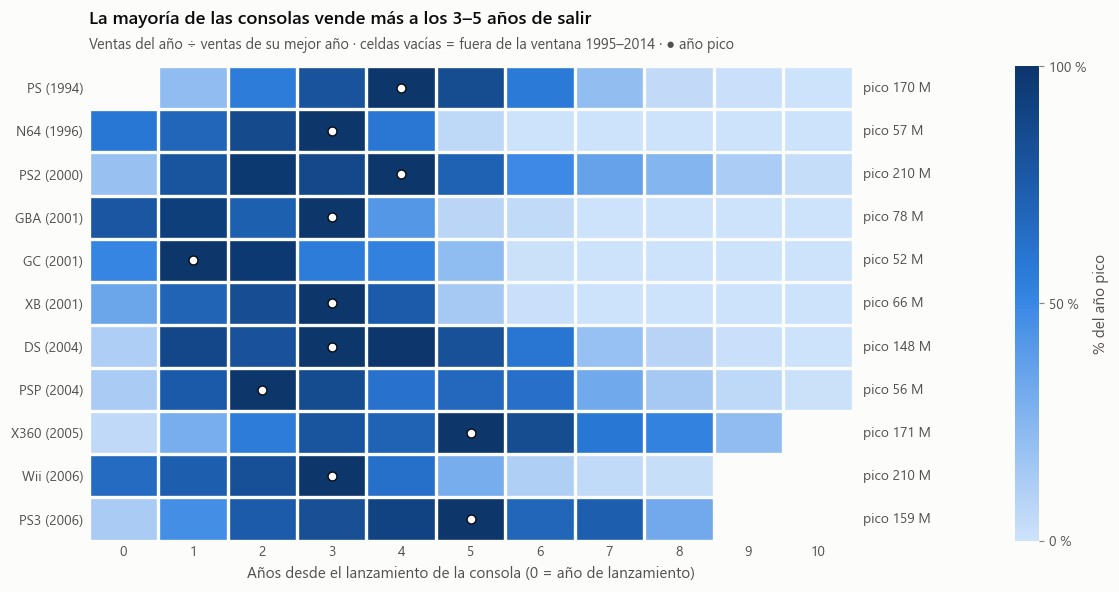

Año de vida del pico: mediana 3, rango 1–5
Tabla de apoyo — ventas por año de vida (M de copias):


,0,1,2,3,4,5,6,7,8,9,10
PS (1994),NaN,36.0,95.0,136.0,170.0,144.0,96.0,36.0,7.0,2.0,0.0
N64 (1996),34.0,39.0,49.0,57.0,34.0,3.0,0.0,0.0,0.0,0.0,0.0
PS2 (2000),39.0,166.0,205.0,184.0,210.0,151.0,102.0,75.0,53.0,26.0,6.0
GBA (2001),61.0,73.0,57.0,78.0,33.0,5.0,3.0,0.0,0.0,0.0,0.0
GC (2001),26.0,52.0,50.0,29.0,28.0,11.0,0.0,0.0,0.0,0.0,0.0
XB (2001),22.0,46.0,55.0,66.0,49.0,9.0,1.0,0.0,0.0,0.0,0.0
DS (2004),17.0,130.0,120.0,148.0,147.0,121.0,88.0,28.0,12.0,2.0,0.0
PSP (2004),7.0,42.0,56.0,47.0,34.0,38.0,35.0,18.0,8.0,3.0,0.0
X360 (2005),8.0,50.0,96.0,136.0,121.0,171.0,145.0,101.0,90.0,36.0,NaN
Wii (2006),138.0,155.0,173.0,210.0,132.0,62.0,23.0,9.0,4.0,NaN,NaN


In [7]:
plats = ["PS", "N64", "PS2", "GBA", "GC", "XB", "DS", "PSP", "X360", "Wii", "PS3"]     # lanzadas antes de 2007 y con >= 300 fichas
ventas_pa = t.groupby(["plataforma", "anio"])["ventas_global"].sum()
edades = np.arange(0, 11)
valores = np.full((len(plats), len(edades)), np.nan)
for i, p in enumerate(plats):
    for j, e in enumerate(edades):
        anio = L.LANZAMIENTO_PLATAFORMA[p] + e
        if L.VENTANA_INICIO <= anio <= L.VENTANA_FIN:                                  # fuera de la ventana no hay datos fiables
            valores[i, j] = ventas_pa.get((p, anio), 0.0)
relativo = valores / np.nanmax(valores, axis=1, keepdims=True) * 100
pico_edad = np.nanargmax(valores, axis=1)
pico_valor = np.nanmax(valores, axis=1)

cmap = estilo.CMAP_SECUENCIAL.copy()
cmap.set_bad(estilo.SUPERFICIE)
fig, ax = plt.subplots(figsize=(11.2, 5.6))
im = ax.imshow(np.ma.masked_invalid(relativo), cmap=cmap, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(edades)
ax.set_yticks(range(len(plats)), [f"{p} ({L.LANZAMIENTO_PLATAFORMA[p]})" for p in plats])
ax.set_xticks(np.arange(-0.5, len(edades), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(plats), 1), minor=True)
ax.grid(which="minor", color=estilo.SUPERFICIE, linewidth=2.2)
ax.grid(which="major", visible=False)
ax.tick_params(which="both", length=0)
for lado in ("left", "bottom"):
    ax.spines[lado].set_visible(False)
ax.set_xlabel("Años desde el lanzamiento de la consola (0 = año de lanzamiento)")
estilo.titular(ax, "La mayoría de las consolas vende más a los 3–5 años de salir", "Ventas del año ÷ ventas de su mejor año · celdas vacías = fuera de la ventana 1995–2014 · ● año pico")
ax.scatter(pico_edad, range(len(plats)), s=34, color="white", edgecolor=estilo.TINTA, linewidth=0.9, zorder=5)
for i in range(len(plats)):
    ax.text(len(edades) - 0.35, i, f"pico {estilo.num(pico_valor[i], 0)} M", va="center", ha="left", fontsize=9, color=estilo.TINTA_2, clip_on=False)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.17, ticks=[0, 50, 100])
cb.ax.set_yticklabels(["0 %", "50 %", "100 %"])
cb.outline.set_visible(False)
cb.set_label("% del año pico", color=estilo.TINTA_2)
estilo.guardar(fig, "fig06_ciclo_de_vida_plataformas.png")
plt.show()

print(f"Año de vida del pico: mediana {np.median(pico_edad):.0f}, rango {pico_edad.min()}–{pico_edad.max()}")
print("Tabla de apoyo — ventas por año de vida (M de copias):")
pd.DataFrame(valores, index=[f"{p} ({L.LANZAMIENTO_PLATAFORMA[p]})" for p in plats], columns=edades).round(0)

In [8]:
tipo = t.groupby("tipo_plataforma").agg(fichas=("exito", "size"), ventas_total=("ventas_global", "sum"),
                                         mediana=("ventas_global", "median"), tasa_exito=("exito", "mean"))
tipo["tasa_exito"] *= 100
u, p_mw = stats.mannwhitneyu(t.loc[t["tipo_plataforma"] == "Portatil", "ventas_global"], t.loc[t["tipo_plataforma"] == "Sobremesa", "ventas_global"])
print(f"Portátil vs sobremesa (Mann–Whitney): p = {p_mw:.1e}")
tipo.round(2)

Portátil vs sobremesa (Mann–Whitney): p = 4.9e-154


,fichas,ventas_total,mediana,tasa_exito
tipo_plataforma,,,,
PC,842,228.45,0.04,7.13
Portatil,4748,1814.74,0.11,7.22
Sobremesa,9144,5743.04,0.23,15.21


> **Hallazgo.** Casi todas las consolas alcanzan su mejor año **3 a 5 años después de salir** (mediana: año 3; el año 0 es el del lanzamiento). Las excepciones son GC (año 1) y PSP (año 2). Después unas mantienen una larga cola (PS, PS2, X360, PS3) y otras se apagan en cuanto pasa el año 5 (N64, GBA, Xbox, GC). No importa solo *qué* consola es, sino *cuánto lleva en el mercado*: de ahí la variable `edad_plataforma` del modelo.
>
> Las portátiles (DS, PSP, GBA…) aportan muchas fichas pero cada una vende mucho menos que las de sobremesa (mediana de 0,11 M frente a 0,23 M; 7 % de éxitos frente a 15 %). El PC es el caso extremo (mediana de 0,04 M): es probable que el dataset registre mal sus ventas, pero eso **no puede comprobarse con estos datos**.

## 4. ¿Qué géneros rinden más?
Hay que separar tres preguntas que suelen mezclarse: *¿qué género suma más ventas?*, *¿cuánto vende un título típico?* y *¿cuál tiene más probabilidad de superar el millón?*

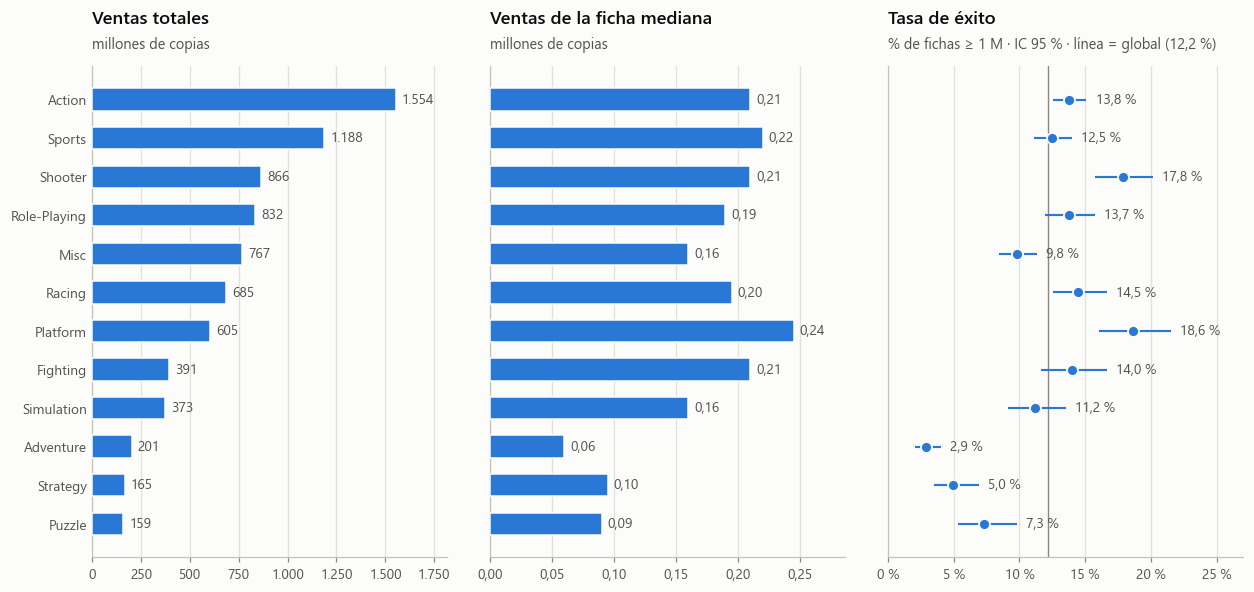

Kruskal–Wallis, ventas ~ género: H = 917, p < 0,001, ε² = 0.062
χ², género × éxito: χ²(11) = 228, p < 0,001, V de Cramér = 0.125
Media ÷ mediana por género: 2.5× a 3.6×



,fichas,total,mediana,media,tasa,ic_bajo,ic_alto
genero,,,,,,,
Action,2770,1553.66,0.21,0.56,13.75,12.52,15.09
Sports,2107,1188.17,0.22,0.56,12.48,11.14,13.96
Shooter,1160,866.26,0.21,0.75,17.84,15.75,20.15
Role-Playing,1274,832.01,0.19,0.65,13.74,11.95,15.74
Misc,1624,766.87,0.16,0.47,9.79,8.44,11.33
Racing,1160,684.63,0.20,0.59,14.48,12.57,16.63
Platform,778,605.17,0.24,0.78,18.64,16.06,21.53
Fighting,745,390.86,0.21,0.52,13.96,11.66,16.63
Simulation,798,372.91,0.16,0.47,11.15,9.15,13.53


In [9]:
def wilson(k, n, z=1.96):
    # intervalo de confianza de Wilson para una proporción
    p = k / n
    d = 1 + z ** 2 / n
    centro = (p + z ** 2 / (2 * n)) / d
    mitad = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return centro - mitad, centro + mitad


gen = t.groupby("genero").agg(fichas=("exito", "size"), total=("ventas_global", "sum"), mediana=("ventas_global", "median"),
                              media=("ventas_global", "mean"), exitos=("exito", "sum"))
gen["tasa"] = gen["exitos"] / gen["fichas"] * 100
gen["ic_bajo"], gen["ic_alto"] = zip(*[(lo * 100, hi * 100) for lo, hi in (wilson(k, n) for k, n in zip(gen["exitos"], gen["fichas"]))])
gen = gen.sort_values("total", ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 5.8), sharey=True, gridspec_kw={"wspace": 0.12})
y = np.arange(len(gen))[::-1]
paneles = [("total", "Ventas totales", "millones de copias", 0), ("mediana", "Ventas de la ficha mediana", "millones de copias", 2)]
for ax, (col, titulo, unidad, dec) in zip(axes[:2], paneles):
    ax.barh(y, gen[col], height=0.58, color=estilo.AZUL, edgecolor=estilo.SUPERFICIE, linewidth=1.0, zorder=3)
    for yi, v in zip(y, gen[col]):
        ax.text(v + gen[col].max() * 0.02, yi, estilo.num(v, dec), va="center", ha="left", fontsize=9, color=estilo.TINTA_2)
    ax.set_xlim(0, gen[col].max() * 1.17)
    estilo.rejilla(ax, "x")
    ax.xaxis.set_major_formatter(estilo.formato_eje(dec if dec else 0))
    estilo.titular(ax, titulo, unidad)
ax = axes[2]
ax.hlines(y, gen["ic_bajo"], gen["ic_alto"], color=estilo.AZUL, lw=1.4, zorder=3)
ax.scatter(gen["tasa"], y, s=52, color=estilo.AZUL, edgecolor=estilo.SUPERFICIE, linewidth=1.2, zorder=4)
for yi, v, hi in zip(y, gen["tasa"], gen["ic_alto"]):
    ax.text(hi + 0.7, yi, estilo.pct(v), va="center", ha="left", fontsize=9, color=estilo.TINTA_2)
ax.axvline(t["exito"].mean() * 100, color=estilo.APAGADO, lw=0.9, zorder=2)
ax.set_xlim(0, 27)
estilo.rejilla(ax, "x")
ax.xaxis.set_major_formatter(estilo.formato_eje(0, " %"))
estilo.titular(ax, "Tasa de éxito", f"% de fichas ≥ 1 M · IC 95 % · línea = global ({estilo.pct(t['exito'].mean() * 100)})")
axes[0].set_yticks(y, gen.index)
for ax_ in axes:
    ax_.tick_params(axis="y", length=0)
estilo.guardar(fig, "fig07_generos.png")
plt.show()

H, p_kw = stats.kruskal(*[g["ventas_global"].to_numpy() for _, g in t.groupby("genero")])
eps2_gen = H * (len(t) + 1) / (len(t) ** 2 - 1)
ct = pd.crosstab(t["genero"], t["exito"])
chi2, p_chi, gl, _ = stats.chi2_contingency(ct)
v_cramer = np.sqrt(chi2 / (len(t) * (min(ct.shape) - 1)))
print(f"Kruskal–Wallis, ventas ~ género: H = {H:.0f}, p {'< 0,001' if p_kw < 0.001 else f'= {p_kw:.3f}'}, ε² = {eps2_gen:.3f}")
print(f"χ², género × éxito: χ²({gl}) = {chi2:.0f}, p {'< 0,001' if p_chi < 0.001 else f'= {p_chi:.3f}'}, V de Cramér = {v_cramer:.3f}")
print(f"Media ÷ mediana por género: {(gen['media'] / gen['mediana']).min():.1f}× a {(gen['media'] / gen['mediana']).max():.1f}×\n")
gen[["fichas", "total", "mediana", "media", "tasa", "ic_bajo", "ic_alto"]].round(2)

> **Hallazgo.** *Action* lidera en volumen (1.554 M) porque tiene muchísimas fichas, pero su ficha mediana (0,21 M) y su tasa de éxito (13,8 %) son del montón. **Platform y Shooter rinden más por título** (18,6 % y 17,8 % de éxitos), y **Adventure, Strategy y Puzzle rinden claramente menos** (3 %–7 %). En todos los géneros la media es entre 2,5 y 3,6 veces la mediana: los superéxitos están en todas partes.
>
> **¿Cuánto importa el género?** Las diferencias son reales (Kruskal–Wallis, *p* < 0,001; los intervalos de Adventure y Strategy no se tocan con los de Platform o Shooter), pero **pequeñas**: ε² = 0,06, o sea, el género separa solo ~6 % de la variación en rangos de ventas. Saber el género ayuda poco; hay que mirar más cosas.

## 5. ¿Cada región tiene gustos distintos?

### 5.1 Qué género pesa más en cada región
Se compara la cuota de cada género en las ventas de una región con su cuota en el mundo. Un índice de 2 significa que el género pesa el doble en esa región que en el total.

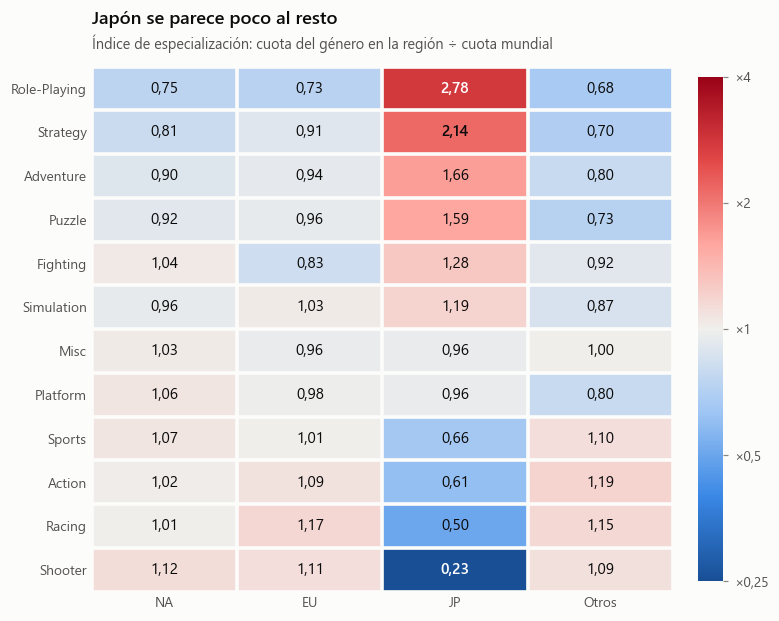

V de Cramér, género × región (sobre copias): 0.164
Cuota de Role-Playing en cada región (%): {'NA': 8.0, 'EU': 7.8, 'JP': 29.7, 'Otros': 7.2}


In [10]:
reg = t.groupby("genero")[L.VENTAS_REGIONALES].sum()
cuota_en_region = reg.div(reg.sum(), axis=1)                          # cuota del género dentro de cada región
cuota_mundial = reg.sum(axis=1) / reg.to_numpy().sum()
indice = cuota_en_region.div(cuota_mundial, axis=0)
indice = indice.loc[indice["ventas_jp"].sort_values(ascending=False).index]
indice.columns = ["NA", "EU", "JP", "Otros"]

logi = np.log2(indice.to_numpy())
norma = TwoSlopeNorm(vmin=-2, vcenter=0, vmax=2)
fig, ax = plt.subplots(figsize=(7.4, 6.2))
im = ax.imshow(np.clip(logi, -2, 2), cmap=estilo.CMAP_DIVERGENTE, norm=norma, aspect="auto")
ax.set_xticks(range(4), indice.columns)
ax.set_yticks(range(len(indice)), indice.index)
ax.set_xticks(np.arange(-0.5, 4, 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(indice), 1), minor=True)
ax.grid(which="minor", color=estilo.SUPERFICIE, linewidth=2.4)
ax.grid(which="major", visible=False)
ax.tick_params(which="both", length=0)
for lado in ax.spines.values():
    lado.set_visible(False)
for i in range(len(indice)):
    for j in range(4):
        valor = indice.iloc[i, j]
        color_celda = to_hex(estilo.CMAP_DIVERGENTE(norma(np.clip(logi[i, j], -2, 2))))
        ax.text(j, i, estilo.num(valor, 2), ha="center", va="center", fontsize=10, color=estilo.tinta_sobre(color_celda),
                fontweight="600" if abs(logi[i, j]) >= 1 else "normal")
estilo.titular(ax, "Japón se parece poco al resto", "Índice de especialización: cuota del género en la región ÷ cuota mundial")
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.04, ticks=[-2, -1, 0, 1, 2])
cb.ax.set_yticklabels(["×0,25", "×0,5", "×1", "×2", "×4"])
cb.outline.set_visible(False)
estilo.guardar(fig, "fig08_gustos_regionales.png")
plt.show()

chi2_r, _, _, _ = stats.chi2_contingency((reg * 1e6).round())
print(f"V de Cramér, género × región (sobre copias): {np.sqrt(chi2_r / (reg.to_numpy().sum() * 1e6 * (min(reg.shape) - 1))):.3f}")
print("Cuota de Role-Playing en cada región (%):", (cuota_en_region.loc['Role-Playing'] * 100).round(1).rename(dict(zip(L.VENTAS_REGIONALES, ['NA', 'EU', 'JP', 'Otros']))).to_dict())

> **Hallazgo.** Norteamérica, Europa y el «resto del mundo» tienen perfiles casi idénticos (índices entre 0,7 y 1,2: *Shooter*, *Sports*, *Action* y *Racing* un poco por encima). **Japón es distinto**: los *Role-Playing* pesan **2,8 veces** más (casi un 30 % de las ventas japonesas frente al 8 % de NA), *Strategy* 2,1×, *Adventure* y *Puzzle* ≈ 1,6×, mientras que *Shooter* pesa apenas **0,23×** y *Racing* 0,5×.
>
> **Para el análisis:** un modelo global puede ocultar que el éxito en Japón y en Occidente responde a recetas distintas. En este proyecto el objetivo es global, pero los 0 regionales (en Japón casi dos de cada tres fichas) no deben leerse como «ventas nulas» (notebook 01).

### 5.2 ¿Cambió el peso de cada región?

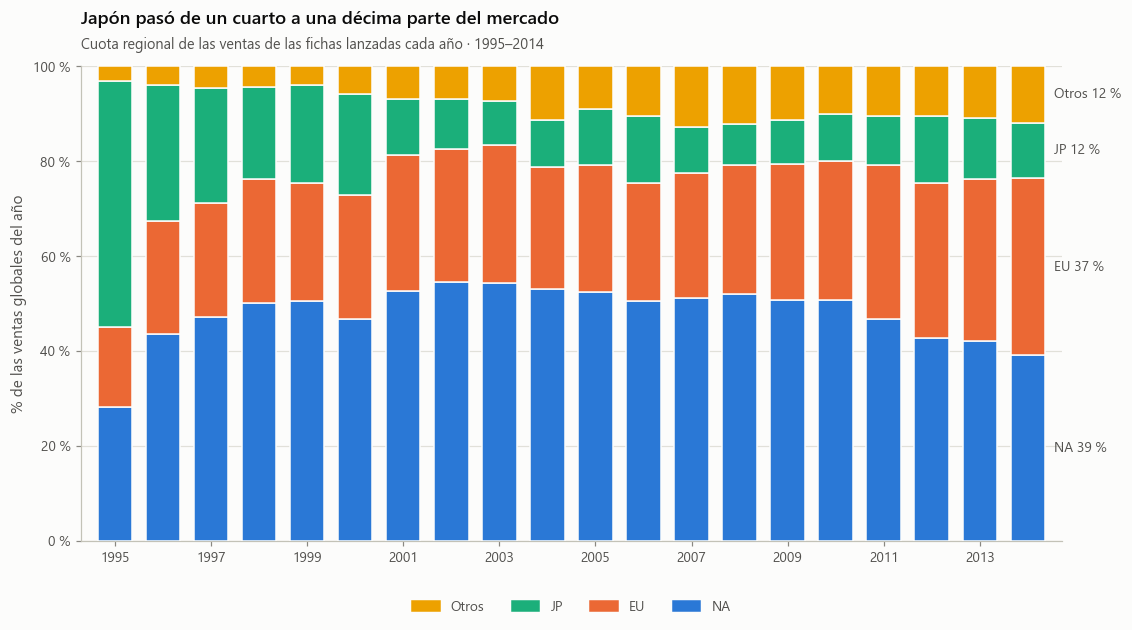

Cuota de Japón: 1995–2004 16.8% → 2005–2014 10.9%  (Δ = -5.9 pp, IC 95 % bootstrap [-7.4, -4.4])

Cuota regional (%) por periodo, y años sueltos como tabla de apoyo de la figura:


,NA,EU,JP,Otros
1995–2004,50.4,26.3,16.8,6.5
2005–2014,48.7,29.4,10.9,11.0
1995,28.2,16.9,51.9,3.0
2000,46.7,26.2,21.3,5.8
2005,52.5,26.7,11.8,9.0
2010,50.7,29.4,9.9,10.0
2014,39.1,37.3,11.7,11.9


In [11]:
cuota_anual = t.groupby(t["anio"].astype(int))[L.VENTAS_REGIONALES].sum()
cuota_anual = cuota_anual.div(cuota_anual.sum(axis=1), axis=0) * 100
cuota_anual.columns = ["NA", "EU", "JP", "Otros"]

fig, ax = plt.subplots(figsize=(11.5, 5.6))
fondo = np.zeros(len(cuota_anual))
for reg_ in ["NA", "EU", "JP", "Otros"]:
    ax.bar(cuota_anual.index, cuota_anual[reg_], bottom=fondo, width=0.72, color=estilo.COLOR_REGION[reg_],
           edgecolor=estilo.SUPERFICIE, linewidth=1.0, zorder=3)
    fondo += cuota_anual[reg_].to_numpy()
ax.set_xlim(1994.3, 2014.7)
ax.set_ylim(0, 100)
ax.set_xticks(range(1995, 2015, 2))
ax.yaxis.set_major_formatter(estilo.formato_eje(0, " %"))
ax.set_ylabel("% de las ventas globales del año")
estilo.titular(ax, "Japón pasó de un cuarto a una décima parte del mercado", "Cuota regional de las ventas de las fichas lanzadas cada año · 1995–2014")
acum = 0
for reg_ in ["NA", "EU", "JP", "Otros"]:                              # etiquetas directas junto al último año
    v = cuota_anual.loc[2014, reg_]
    ax.text(2014.55, acum + v / 2, f"{reg_} {estilo.pct(v, 0)}", va="center", ha="left", fontsize=9, color=estilo.TINTA_2, clip_on=False)
    acum += v
ax.legend(handles=[Patch(color=estilo.COLOR_REGION[r], label=r) for r in ["Otros", "JP", "EU", "NA"]], loc="upper center",
          bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False)
estilo.guardar(fig, "fig09_cuota_regional_por_anio.png")
plt.show()

# H4: la cuota de Japón bajó entre 1995-2004 y 2005-2014 (bootstrap de fichas)
rng = np.random.default_rng(SEMILLA)
e1, e2 = t[t["anio"] <= 2004], t[t["anio"] >= 2005]
def cuota_jp(d):
    return d["ventas_jp"].sum() / d[L.VENTAS_REGIONALES].sum().sum()
dif_obs = cuota_jp(e2) - cuota_jp(e1)
dif_boot = [cuota_jp(e2.iloc[rng.integers(0, len(e2), len(e2))]) - cuota_jp(e1.iloc[rng.integers(0, len(e1), len(e1))]) for _ in range(1000)]
ic_jp = np.percentile(dif_boot, [2.5, 97.5])
print(f"Cuota de Japón: 1995–2004 {cuota_jp(e1):.1%} → 2005–2014 {cuota_jp(e2):.1%}  (Δ = {dif_obs * 100:+.1f} pp, IC 95 % bootstrap [{ic_jp[0] * 100:+.1f}, {ic_jp[1] * 100:+.1f}])")

periodos = pd.DataFrame({"1995–2004": e1[L.VENTAS_REGIONALES].sum(), "2005–2014": e2[L.VENTAS_REGIONALES].sum()}).T
periodos = periodos.div(periodos.sum(axis=1), axis=0) * 100
periodos.columns = ["NA", "EU", "JP", "Otros"]
print("\nCuota regional (%) por periodo, y años sueltos como tabla de apoyo de la figura:")
pd.concat([periodos, cuota_anual.loc[[1995, 2000, 2005, 2010, 2014]]]).round(1)

> **Hallazgo.** La cuota de Japón cae de ≈ 17 % (1995–2004) a ≈ 11 % (2005–2014): **−5,9 puntos porcentuales** (IC 95 % bootstrap entre −7,4 y −4,4). Europa gana peso (de ≈ 26 % a ≈ 29 %; en 2014 casi iguala a Norteamérica, 37 % frente a 39 %) y el «resto del mundo» pasa de ≈ 7 % a ≈ 11 %. Los años 1995–1996 son poco fiables (pocas fichas, y 1995 tiene un 52 % de Japón sobre solo 219 fichas).
>
> **Cautela:** la caída tras 2011 de la cobertura del dataset (notebook 01) puede alterar las cuotas de los últimos años; la tendencia 1995–2010 es la más sólida.

## 6. ¿Importan el publisher, la franquicia y salir en varias plataformas?

### 6.1 Publishers: volumen no es rendimiento

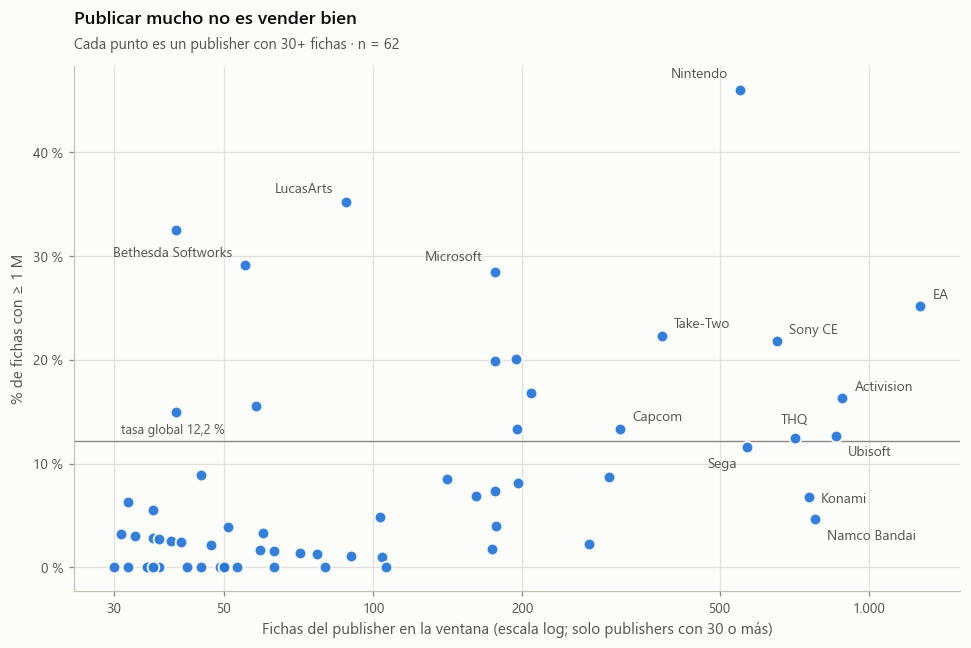

Tasa de éxito: Nintendo 46.0% (550 fichas) frente al 10.9% del resto · mediana de ventas 0.79 M frente a 0.16 M



,fichas,total,mediana,tasa
publisher,,,,
Nintendo,550,1381.95,0.79,46.00
Electronic Arts,1269,1027.33,0.48,25.22
Activision,884,658.55,0.28,16.29
Sony Computer Entertainment,652,583.73,0.34,21.78
Ubisoft,859,448.39,0.22,12.69
Take-Two Interactive,382,380.09,0.30,22.25
THQ,708,338.98,0.27,12.43
Konami Digital Entertainment,757,250.21,0.14,6.74
Sega,569,242.77,0.20,11.60


In [12]:
pub = (t[t["publisher"].notna()].groupby("publisher")
         .agg(fichas=("exito", "size"), total=("ventas_global", "sum"), mediana=("ventas_global", "median"), exitos=("exito", "sum")))
pub["tasa"] = pub["exitos"] / pub["fichas"] * 100
pub = pub[pub["fichas"] >= 30].sort_values("total", ascending=False)

cortos = {"Electronic Arts": "EA", "Sony Computer Entertainment": "Sony CE", "Take-Two Interactive": "Take-Two",
          "Konami Digital Entertainment": "Konami", "Namco Bandai Games": "Namco Bandai", "Microsoft Game Studios": "Microsoft",
          "Warner Bros. Interactive Entertainment": "Warner Bros."}
etiquetar = list(pub.head(12).index) + ["Bethesda Softworks", "LucasArts"]
ajuste = {"Nintendo": (-8, 8, "right"), "Electronic Arts": (8, 5, "left"), "Activision": (8, 5, "left"), "Sony Computer Entertainment": (8, 5, "left"),
          "Ubisoft": (8, -13, "left"), "Take-Two Interactive": (8, 6, "left"), "THQ": (0, 10, "center"), "Konami Digital Entertainment": (8, -3, "left"),
          "Sega": (-7, -13, "right"), "Namco Bandai Games": (8, -13, "left"), "Microsoft Game Studios": (-8, 8, "right"),
          "Capcom": (8, 6, "left"), "Bethesda Softworks": (-8, 6, "right"), "LucasArts": (-8, 6, "right")}

fig, ax = plt.subplots(figsize=(10.4, 6.2))
ax.scatter(pub["fichas"], pub["tasa"], s=58, color=estilo.AZUL, edgecolor=estilo.SUPERFICIE, linewidth=1.2, zorder=3, alpha=0.95)
ax.set_xscale("log")
ax.set_xticks([30, 50, 100, 200, 500, 1000], ["30", "50", "100", "200", "500", "1.000"])
ax.minorticks_off()
estilo.rejilla(ax, "ambos")
ax.yaxis.set_major_formatter(estilo.formato_eje(0, " %"))
ax.set_xlabel("Fichas del publisher en la ventana (escala log; solo publishers con 30 o más)")
ax.set_ylabel("% de fichas con ≥ 1 M")
estilo.titular(ax, "Publicar mucho no es vender bien", f"Cada punto es un publisher con 30+ fichas · n = {len(pub)}")
ax.axhline(t["exito"].mean() * 100, color=estilo.APAGADO, lw=0.9, zorder=2)
ax.text(31, t["exito"].mean() * 100 + 0.7, f"tasa global {estilo.pct(t['exito'].mean() * 100)}", ha="left", fontsize=8.5, color=estilo.TINTA_2)
for nombre in etiquetar:
    if nombre in pub.index:
        dx, dy, ha = ajuste.get(nombre, (8, 5, "left"))
        ax.annotate(cortos.get(nombre, nombre), (pub.loc[nombre, "fichas"], pub.loc[nombre, "tasa"]), xytext=(dx, dy),
                    textcoords="offset points", fontsize=9, color=estilo.TINTA_2, ha=ha)
estilo.guardar(fig, "fig10_publishers.png")
plt.show()

es_nintendo = t["publisher"].eq("Nintendo")
print(f"Tasa de éxito: Nintendo {t.loc[es_nintendo, 'exito'].mean():.1%} ({int(es_nintendo.sum())} fichas) frente al {t.loc[~es_nintendo, 'exito'].mean():.1%} del resto "
      f"· mediana de ventas {t.loc[es_nintendo, 'ventas_global'].median():.2f} M frente a {t.loc[~es_nintendo, 'ventas_global'].median():.2f} M\n")
pub.head(12)[["fichas", "total", "mediana", "tasa"]].round(2)

> **Hallazgo.** **Nintendo** es un caso aparte: **46 %** de sus fichas supera el millón (frente al 11 % del resto) y su ficha mediana vende 0,79 M, casi cinco veces la mediana global. Después vienen Microsoft (28 %), EA (25 %), Take-Two (22 %) y Sony (22 %). En el otro extremo, publishers enormes como **Namco Bandai (777 fichas, 4,6 %)** o **Konami (757 fichas, 6,7 %)** publican muchísimo y rara vez llegan al millón. Que haya tantas fichas de un publisher no dice nada sobre cuántas triunfan.
>
> Una aclaración: la identidad del publisher mezcla varias cosas (marca, presupuesto, plataformas propias, tipo de juego). Es un **excelente separador** de éxitos, pero este análisis no dice *por qué*.

### 6.2 Franquicia y versiones simultáneas
Dos ideas de negocio: *las secuelas venden más que los títulos nuevos* y *salir en más plataformas ayuda*. Ambas están mezcladas con el tamaño del publisher (los grandes tienen más sagas y publican en más plataformas), así que hay que separarlas. Se estratifica por tamaño de publisher.

In [13]:
tam_pub = t["publisher"].map(t.groupby("publisher").size()).fillna(0)
t["tam_publisher"] = np.select([tam_pub >= 200, tam_pub >= 40], ["grande (200+ fichas)", "mediano (40–199)"], "pequeño o desconocido (< 40)")
t["con_historial"] = t["fr_n_prev"] > 0               # la saga tuvo alguna entrega en un año anterior
t["multi"] = t["n_versiones"] >= 3                     # salió a la vez en 3 o más plataformas


def or_cruda(d, exp):
    a, b = ((d[exp]) & (d["exito"] == 1)).sum(), ((d[exp]) & (d["exito"] == 0)).sum()
    c, dd = ((~d[exp]) & (d["exito"] == 1)).sum(), ((~d[exp]) & (d["exito"] == 0)).sum()
    est = (a * dd) / (b * c)
    se = np.sqrt(1 / a + 1 / b + 1 / c + 1 / dd)
    return est, np.exp(np.log(est) - 1.96 * se), np.exp(np.log(est) + 1.96 * se)


def or_mantel_haenszel(d, exp, estrato="tam_publisher"):
    # odds ratio común a todos los estratos (Mantel–Haenszel)
    num = den = 0.0
    for _, g in d.groupby(estrato):
        a, b = ((g[exp]) & (g["exito"] == 1)).sum(), ((g[exp]) & (g["exito"] == 0)).sum()
        c, dd = ((~g[exp]) & (g["exito"] == 1)).sum(), ((~g[exp]) & (g["exito"] == 0)).sum()
        n = a + b + c + dd
        num += a * dd / n
        den += b * c / n
    return num / den


resultados = {}
rng = np.random.default_rng(SEMILLA)
for exp, nombre in [("con_historial", "Saga con entregas previas"), ("multi", "Salió en 3+ plataformas a la vez")]:
    est, lo, hi = or_cruda(t, exp)
    mh = or_mantel_haenszel(t, exp)
    boot = [or_mantel_haenszel(t.iloc[rng.integers(0, len(t), len(t))], exp) for _ in range(500)]
    resultados[nombre] = dict(cruda=est, cruda_ic=(lo, hi), mh=mh, mh_ic=tuple(np.percentile(boot, [2.5, 97.5])))
    print(f"{nombre}: OR crudo = {est:.2f} [{lo:.2f}, {hi:.2f}]  →  ajustado por tamaño del publisher (M–H) = {mh:.2f} [{resultados[nombre]['mh_ic'][0]:.2f}, {resultados[nombre]['mh_ic'][1]:.2f}]")
    print(f"   tasa de éxito: {t.loc[t[exp], 'exito'].mean():.1%} (n = {int(t[exp].sum()):,}) con la característica vs {t.loc[~t[exp], 'exito'].mean():.1%} (n = {int((~t[exp]).sum()):,}) sin ella")

Saga con entregas previas: OR crudo = 1.87 [1.70, 2.07]  →  ajustado por tamaño del publisher (M–H) = 1.61 [1.46, 1.79]
   tasa de éxito: 16.2% (n = 6,035) con la característica vs 9.4% (n = 8,699) sin ella


Salió en 3+ plataformas a la vez: OR crudo = 1.64 [1.47, 1.82]  →  ajustado por tamaño del publisher (M–H) = 1.30 [1.16, 1.45]
   tasa de éxito: 16.5% (n = 3,600) con la característica vs 10.8% (n = 11,134) sin ella


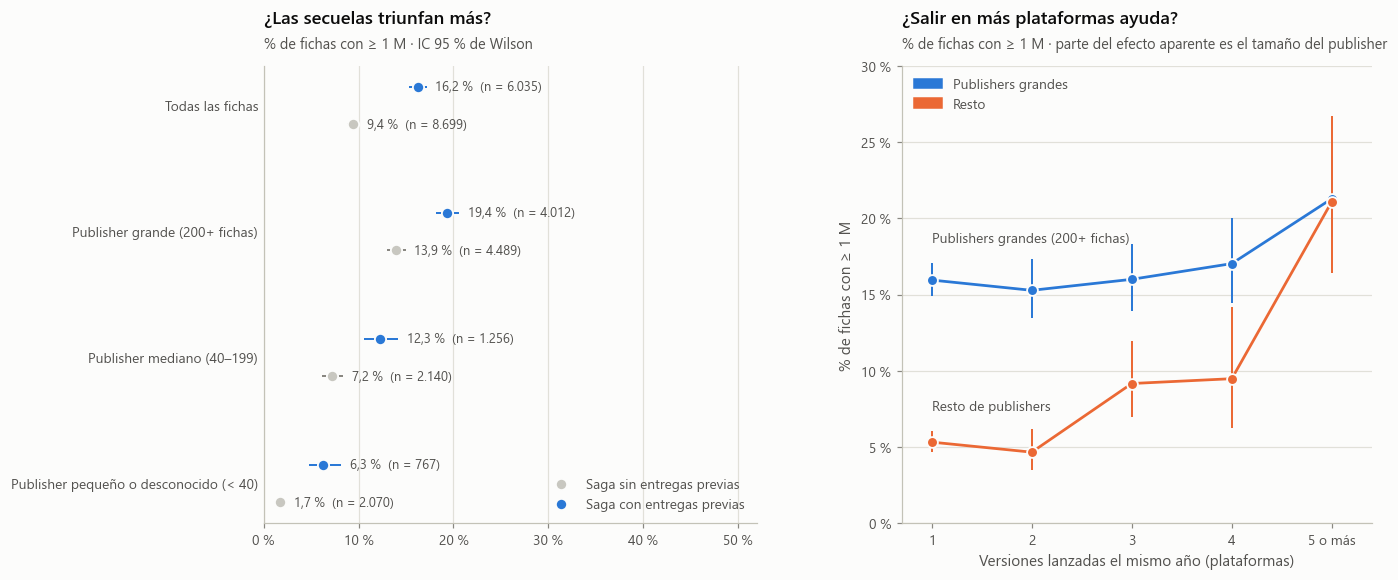

fichas          tasa      
publisher   grandes resto grandes resto
n_versiones                            
1              4546  4306    15.9   5.3
2              1316   966    15.3   4.7
3              1044   513    16.0   9.2
4               693   211    17.0   9.5
5               902   237    21.3  21.1

In [14]:
orden_tam = ["grande (200+ fichas)", "mediano (40–199)", "pequeño o desconocido (< 40)"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={"wspace": 0.3, "width_ratios": [1.05, 1]})

# --- (a) tasa de éxito con y sin historial de franquicia, por tamaño de publisher
filas = [("Todas las fichas", t)] + [(f"Publisher {n}", t[t["tam_publisher"] == n]) for n in orden_tam]
y = np.arange(len(filas))[::-1]
for desfase, flag, color, etiqueta in [(-0.15, False, estilo.GRIS_FONDO, "Saga sin entregas previas"), (0.15, True, estilo.AZUL, "Saga con entregas previas")]:
    for yi, (nombre, d) in zip(y, filas):
        sub = d[d["con_historial"] == flag]
        k, n = sub["exito"].sum(), len(sub)
        lo, hi = wilson(k, n)
        ax1.hlines(yi + desfase, lo * 100, hi * 100, color=estilo.APAGADO if color == estilo.GRIS_FONDO else color, lw=1.3, zorder=3)
        ax1.scatter([k / n * 100], [yi + desfase], s=54, color=color, edgecolor=estilo.SUPERFICIE, linewidth=1.2, zorder=4,
                    label=etiqueta if yi == y[0] else None)
        ax1.text(hi * 100 + 0.9, yi + desfase, f"{estilo.pct(k / n * 100)}  (n = {estilo.num(n)})", va="center", fontsize=8.5, color=estilo.TINTA_2)
ax1.set_yticks(y, [f[0] for f in filas])
ax1.tick_params(axis="y", length=0)
ax1.set_xlim(0, 52)
estilo.rejilla(ax1, "x")
ax1.xaxis.set_major_formatter(estilo.formato_eje(0, " %"))
ax1.legend(loc="lower right", frameon=False)
estilo.titular(ax1, "¿Las secuelas triunfan más?", "% de fichas con ≥ 1 M · IC 95 % de Wilson")

# --- (b) tasa de éxito según versiones simultáneas, publishers grandes vs. el resto
grande = t["tam_publisher"] == orden_tam[0]
for flag, color, nombre in [(True, estilo.AZUL, "Publishers grandes (200+ fichas)"), (False, estilo.NARANJA, "Resto de publishers")]:
    sub = t[grande == flag]
    g = sub.groupby(sub["n_versiones"].clip(upper=5)).agg(n=("exito", "size"), k=("exito", "sum"))
    tasa_v = g["k"] / g["n"] * 100
    ic = np.array([wilson(k, n) for k, n in zip(g["k"], g["n"])]) * 100
    ax2.vlines(g.index, ic[:, 0], ic[:, 1], color=color, lw=1.3, zorder=3)
    ax2.plot(g.index, tasa_v, color=color, lw=1.8, zorder=3)
    ax2.scatter(g.index, tasa_v, s=50, color=color, edgecolor=estilo.SUPERFICIE, linewidth=1.2, zorder=4)
    ax2.text(1.0, ic[0, 1] + 1.2, nombre, va="bottom", ha="left", fontsize=9, color=estilo.TINTA_2)   # rotulo donde las series NO se cruzan
ax2.set_xlim(0.7, 5.4)
ax2.set_ylim(0, 30)
ax2.set_xticks(range(1, 6), ["1", "2", "3", "4", "5 o más"])
ax2.yaxis.set_major_formatter(estilo.formato_eje(0, " %"))
estilo.rejilla(ax2, "y")
ax2.set_xlabel("Versiones lanzadas el mismo año (plataformas)")
ax2.set_ylabel("% de fichas con ≥ 1 M")
ax2.legend(handles=[Patch(color=estilo.AZUL, label="Publishers grandes"), Patch(color=estilo.NARANJA, label="Resto")], loc="upper left", frameon=False)
estilo.titular(ax2, "¿Salir en más plataformas ayuda?", "% de fichas con ≥ 1 M · parte del efecto aparente es el tamaño del publisher")
estilo.guardar(fig, "fig11_franquicia_y_versiones.png")
plt.show()

tabla_v = t.groupby([grande.map({True: "grandes", False: "resto"}).rename("publisher"), t["n_versiones"].clip(upper=5)]).agg(fichas=("exito", "size"), tasa=("exito", "mean"))
tabla_v["tasa"] = (tabla_v["tasa"] * 100).round(1)
tabla_v.unstack(0)

> **Hallazgo 1 · Franquicia.** Las sagas con entregas previas triunfan más (16 % frente a 9 %; odds ratio crudo 1,87) y la diferencia **se mantiene dentro de cada tamaño de publisher** (19 % vs 14 % entre los grandes, 12 % vs 7 % entre los medianos, 6 % vs 2 % entre los pequeños). Al ajustar por tamaño (Mantel–Haenszel) el OR baja a 1,61 (IC 95 % 1,46–1,79): parte de lo que parecía «efecto saga» era «efecto publisher grande», pero la mayor parte persiste. El historial de la saga aporta información propia, y es la variable que se construye con más cuidado en el notebook 03.
>
> **Hallazgo 2 · Versiones simultáneas.** Salir en 3 o más plataformas a la vez parece multiplicar las probabilidades (OR crudo 1,64), pero **cerca de la mitad de ese efecto es confusión con el tamaño del publisher**: ajustado baja a 1,30 (IC 95 % 1,16–1,45). La tabla lo muestra: entre los publishers grandes la tasa es ≈ 16 % con 1, 2 o 3 versiones y solo sube con 5 o más (21 %); en el resto sube antes (de ≈ 5 % a ≈ 9 % con 3–4 versiones) y también llega a ≈ 21 % con 5 o más. Lo único que se ve igual en ambos grupos son los lanzamientos masivos en 5 o más plataformas, que probablemente reflejan una apuesta comercial fuerte (algo que el dataset no mide).
>
> Moraleja metodológica: antes de atribuirle un efecto a una variable hay que preguntar qué otra variable se mueve con ella.

## 7. ¿Qué variable separa mejor las ventas?
Para cerrar el recorrido, una comparación a la misma vara: cuánto separa cada variable los niveles de ventas de una ficha (ε² de Kruskal–Wallis; 0 = nada, 1 = separa por completo). Los publishers pequeños se agrupan en «Otros» (como hará el modelo).

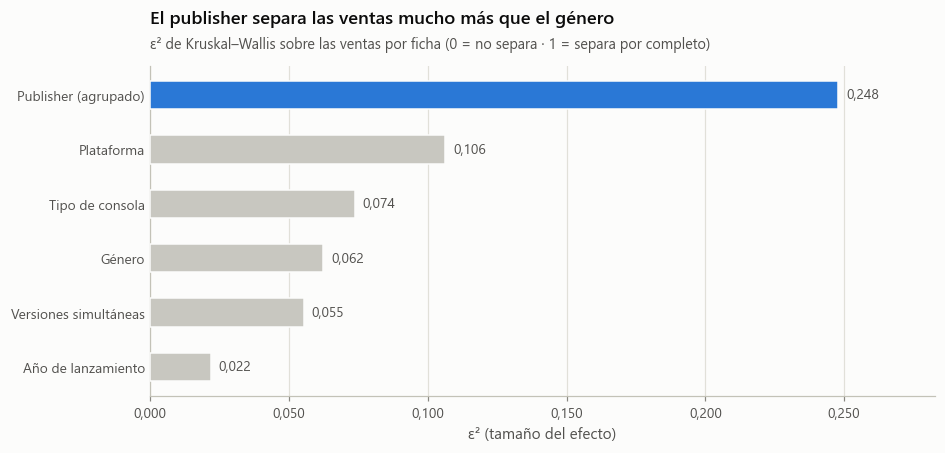

,variable,eps2,p
0,Publisher (agrupado),0.248,"< 0,001"
1,Plataforma,0.106,"< 0,001"
2,Tipo de consola,0.074,"< 0,001"
3,Género,0.062,"< 0,001"
4,Versiones simultáneas,0.055,"< 0,001"
5,Año de lanzamiento,0.022,"< 0,001"


In [15]:
def epsilon2(d, variable):
    grupos = [g["ventas_global"].to_numpy() for _, g in d.groupby(variable) if len(g) >= 2]
    H, p = stats.kruskal(*grupos)
    n = sum(len(g) for g in grupos)
    return H * (n + 1) / (n ** 2 - 1), p


t["versiones_cat"] = t["n_versiones"].clip(upper=5)
variables = {"Publisher (agrupado)": "publisher_grp", "Plataforma": "plataforma", "Año de lanzamiento": "anio",
             "Género": "genero", "Tipo de consola": "tipo_plataforma", "Versiones simultáneas": "versiones_cat"}
sep = pd.DataFrame([(nombre, *epsilon2(t, col)) for nombre, col in variables.items()], columns=["variable", "eps2", "p"])
sep = sep.sort_values("eps2", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9.2, 3.9))
colores = [estilo.AZUL] + [estilo.GRIS_FONDO] * (len(sep) - 1)
estilo.barras_h(ax, sep["variable"], sep["eps2"], colores=colores, decimales=3, alto=0.52)
estilo.titular(ax, "El publisher separa las ventas mucho más que el género", "ε² de Kruskal–Wallis sobre las ventas por ficha (0 = no separa · 1 = separa por completo)")
ax.set_xlabel("ε² (tamaño del efecto)")
estilo.guardar(fig, "fig12_variables_que_separan_ventas.png")
plt.show()

sep.assign(p=lambda d: d["p"].map(lambda v: "< 0,001" if v < 0.001 else f"{v:.3f}")).round(3)

> **Hallazgo.** El **publisher** es, con diferencia, la variable que mejor separa los niveles de ventas (ε² = 0,25): más de cuatro veces el género (0,06) y más del doble que la plataforma (0,11). El **año calendario casi no separa** (0,02): lo que importa no es *cuándo* sale un juego sino *en qué momento de la vida de su consola*, lo que refuerza usar `edad_plataforma` en lugar del año en el modelo. La enseñanza es que el éxito se explica más por *quién publica y en qué plataforma* que por el tipo de juego. (Estas cifras son univariantes y se solapan: un publisher grande suele ir con unas plataformas y unas épocas concretas. La comparación conjunta está en el notebook 03.)

## 8. Resumen de hipótesis y lecturas

| # | Pregunta | Prueba | Resultado | Lectura |
|---|---|---|---|---|
| H1 | ¿Cambian las ventas según el género? | Kruskal–Wallis | *p* < 0,001 · ε² = 0,06 | Diferencias reales pero pequeñas |
| H2 | ¿Las sagas con entregas previas triunfan más? | Odds ratio, crudo y ajustado por tamaño de publisher (Mantel–Haenszel) | OR 1,87 → 1,61 (IC 95 % 1,46–1,79) | Sí; sobrevive al ajuste |
| H3 | ¿Salir en 3+ plataformas a la vez aumenta el éxito? | Odds ratio, crudo y ajustado | OR 1,64 → 1,30 (IC 95 % 1,16–1,45) | El efecto se reduce a la mitad: era en buena parte **confusión** con el tamaño del publisher |
| H4 | ¿Cayó el peso de Japón entre 1995–2004 y 2005–2014? | Bootstrap de la diferencia de cuotas | −5,9 pp (IC 95 % −7,4 a −4,4) | Sí |
| H5 | ¿Tienen Japón y Occidente gustos distintos por género? | V de Cramér + índice de especialización | V = 0,16 · RPG ×2,8, Shooter ×0,23 en Japón | Sí; Japón es quien se desmarca |

## 9. Conclusiones y qué se lleva al modelo

1. **El éxito es una cola larga.** El 10 % de las fichas vende el 58 % del total y la media triplica la mediana. Se usan medianas y tasa de éxito, y el objetivo del modelo es binario (`exito`).
2. **Importa *quién* y *en qué plataforma* mucho más que *qué*.** El publisher (ε² = 0,25) y la plataforma (0,11) separan las ventas mejor que el género (0,06). Nintendo es un caso aparte (46 % de éxitos). El año calendario casi no separa (0,02).
3. **Las consolas tienen ciclo de vida**: el mejor año suele llegar 3–5 años después del lanzamiento. De ahí `edad_plataforma` en lugar del año.
4. **Las sagas con historial tienen ventaja** que persiste al comparar publishers del mismo tamaño (OR ajustado 1,61) → se construye el historial de franquicia en el modelo, con cuidado para no mirar al futuro.
5. **Cuidado con la confusión**: «salir en más plataformas» parece ayudar (OR 1,64), pero cerca de la mitad del efecto es el tamaño del publisher (ajustado 1,30).
6. **Japón es otro mercado** (gustos y evolución). El objetivo del proyecto es global; un modelo por región sería un siguiente paso natural.

**Variables candidatas para el modelo:** `plataforma`, `genero`, `publisher` (agrupado), `edad_plataforma`, `n_versiones` e historial de la franquicia. **Nunca:** `rank_original`, las ventas regionales ni `ventas_global` (notebook 01).

**Siguiente:** [03 · Modelado](03_modelado_exito_comercial.ipynb).